# Titanic Survival Prediction Using CART

# Step 1: Import Libraries and Load Dataset

## Objective
Import the required Python libraries and load the Titanic dataset for machine learning.

## Libraries Used
- Pandas: Data manipulation and analysis.
- NumPy: Numerical operations.
- Matplotlib and Seaborn: Data visualization.
- Scikit-learn: Machine learning and model evaluation.
- Joblib: Saving and loading the trained model.

## Dataset
We use the Titanic dataset available through Seaborn.

The dataset contains passenger information such as age, gender, passenger class, fare, and survival status.

## Target Variable
- 0 – Did Not Survive
- 1 – Survived

## Expected Outcome
Successfully load the dataset and inspect its first five records.

In [56]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the original Titanic dataset
df = sns.load_dataset("titanic")

# Display first five records
print(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Dataset Shape: (891, 15)


# Step 2: Data Understanding and Cleaning

## Objective
Understand the dataset structure and prepare the required columns for machine learning.

## Activities
1. Check the dataset dimensions.
2. Inspect column names and data types.
3. Identify missing values.
4. Check duplicate records.
5. Select relevant columns.
6. Remove unnecessary and redundant columns.

## Selected Features
- Pclass
- Sex
- Age
- SibSp
- Parch
- Fare
- Embarked

## Target Variable
- Survived

## Expected Outcome
Obtain a dataset containing the seven independent features and one dependent variable, ready for further analysis.

In [57]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Select required columns
df_clean = df[
    [
        "survived",
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked"
    ]
].copy()

# Verify selected dataset
print("\nCleaned Dataset Shape:", df_clean.shape)
print(df_clean.head())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB

Missing Values:
survived         0
pclass           0
sex              0
age            177


# Step 3: Exploratory Data Analysis (EDA)

## Objective
Explore the Titanic dataset to identify patterns, relationships, and trends that may influence passenger survival.

## Analysis Performed

1. Survival Count Analysis
   - Compare the number of passengers who survived and did not survive.

2. Gender-Based Survival Analysis
   - Understand survival rates among male and female passengers.

3. Passenger Class Analysis
   - Compare survival rates across different passenger classes.

4. Age Distribution Analysis
   - Understand the age distribution of passengers.

## Libraries Used
- Matplotlib
- Seaborn
- Pandas

## Expected Outcome
Understand important patterns in the dataset and identify features that may contribute to survival prediction.

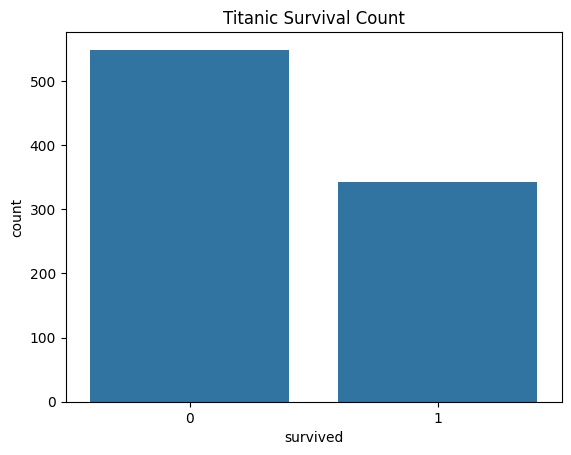

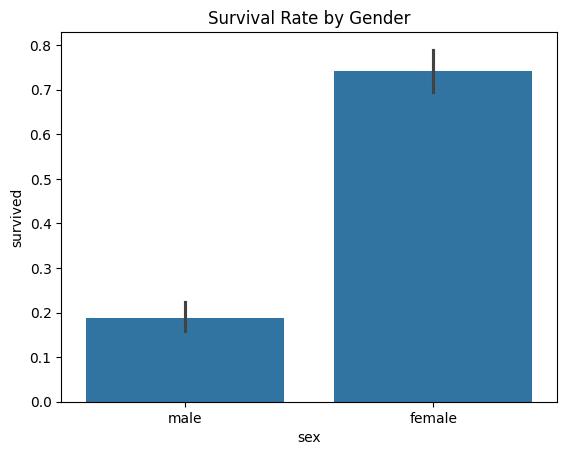

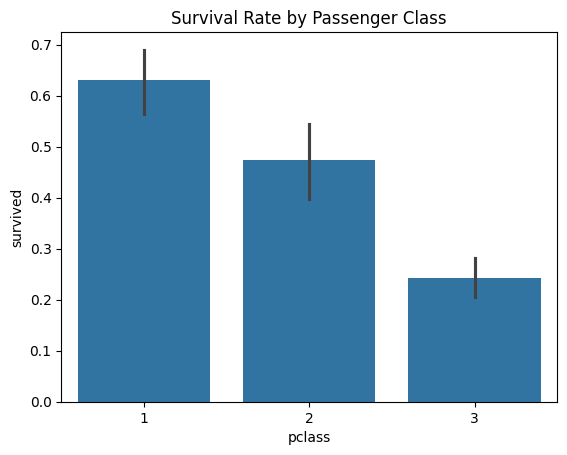

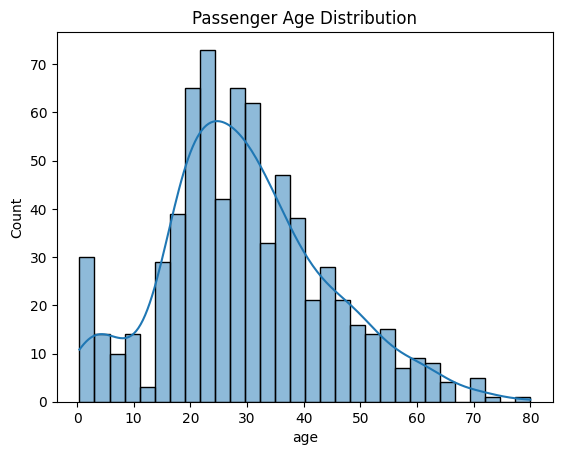

In [58]:
# Survival count
sns.countplot(data=df_clean, x="survived")
plt.title("Titanic Survival Count")
plt.show()

# Survival based on gender
sns.barplot(data=df_clean, x="sex", y="survived")
plt.title("Survival Rate by Gender")
plt.show()

# Survival based on passenger class
sns.barplot(data=df_clean, x="pclass", y="survived")
plt.title("Survival Rate by Passenger Class")
plt.show()

# Age distribution
sns.histplot(data=df_clean, x="age", bins=30, kde=True)
plt.title("Passenger Age Distribution")
plt.show()

# Step 4: Feature Selection and Preprocessing

## Objective
Select independent and dependent variables and prepare the data for the CART algorithm.

## Feature Selection

Independent Variables (X):
- Pclass
- Sex
- Age
- SibSp
- Parch
- Fare
- Embarked

Dependent Variable (y):
- Survived

## Data Preprocessing

1. Missing Value Imputation
   - Numerical features: Median imputation.
   - Categorical features: Most frequent value imputation.

2. Categorical Encoding
   - Apply One-Hot Encoding to convert categorical values into numerical representations.

3. ColumnTransformer
   - Combine numerical and categorical preprocessing operations.

## Expected Outcome
Prepare a preprocessing pipeline that handles missing values and converts categorical features into numerical data.

In [59]:
# Independent variables
X = df_clean[
    ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
]

# Dependent variable
y = df_clean["survived"]

# Identify numerical and categorical features
numerical_features = [
    "pclass", "age", "sibsp", "parch", "fare"
]

categorical_features = ["sex", "embarked"]

# Handle numerical missing values
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Handle categorical missing values and encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (891, 7)
Target Shape: (891,)


# Step 5: Train-Test Split

## Objective
Divide the dataset into training and testing subsets to evaluate the performance of the CART model.

## Data Splitting
- Training Data: 80%
- Testing Data: 20%

## Parameters Used
- test_size = 0.20
- random_state = 42
- stratify = y

## Preprocessing Execution
1. Fit the preprocessing pipeline using training data.
2. Transform the training data.
3. Transform the testing data using the same fitted pipeline.

## Why Train-Test Split?
Training data is used to teach the model, while testing data evaluates its performance on unseen records.

## Expected Outcome
Obtain preprocessed training and testing datasets ready for CART model training.

In [60]:
# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing using training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (712, 10)
Testing Shape: (179, 10)


# Step 6: CART Model Training and Evaluation

## Objective
Implement the Classification and Regression Tree (CART) algorithm to predict Titanic passenger survival.

## Algorithm
CART – Classification and Regression Tree.

## Model Configuration
- criterion = Gini
- max_depth = 4
- min_samples_split = 10
- min_samples_leaf = 5
- random_state = 42

## Model Training
Train the DecisionTreeClassifier using the preprocessed training dataset.

## Model Evaluation

Evaluate the model using:

1. Accuracy Score
2. Confusion Matrix
3. Precision
4. Recall
5. F1-Score
6. Classification Report

## Decision Tree Visualization
Visualize the trained CART model to understand its decision rules and feature-based splits.

## Expected Outcome
Understand how the CART algorithm makes predictions and evaluate its classification performance.

CART Model Accuracy: 77.65 %

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179



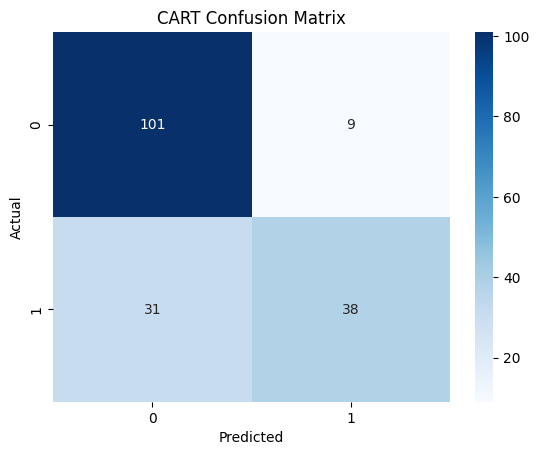

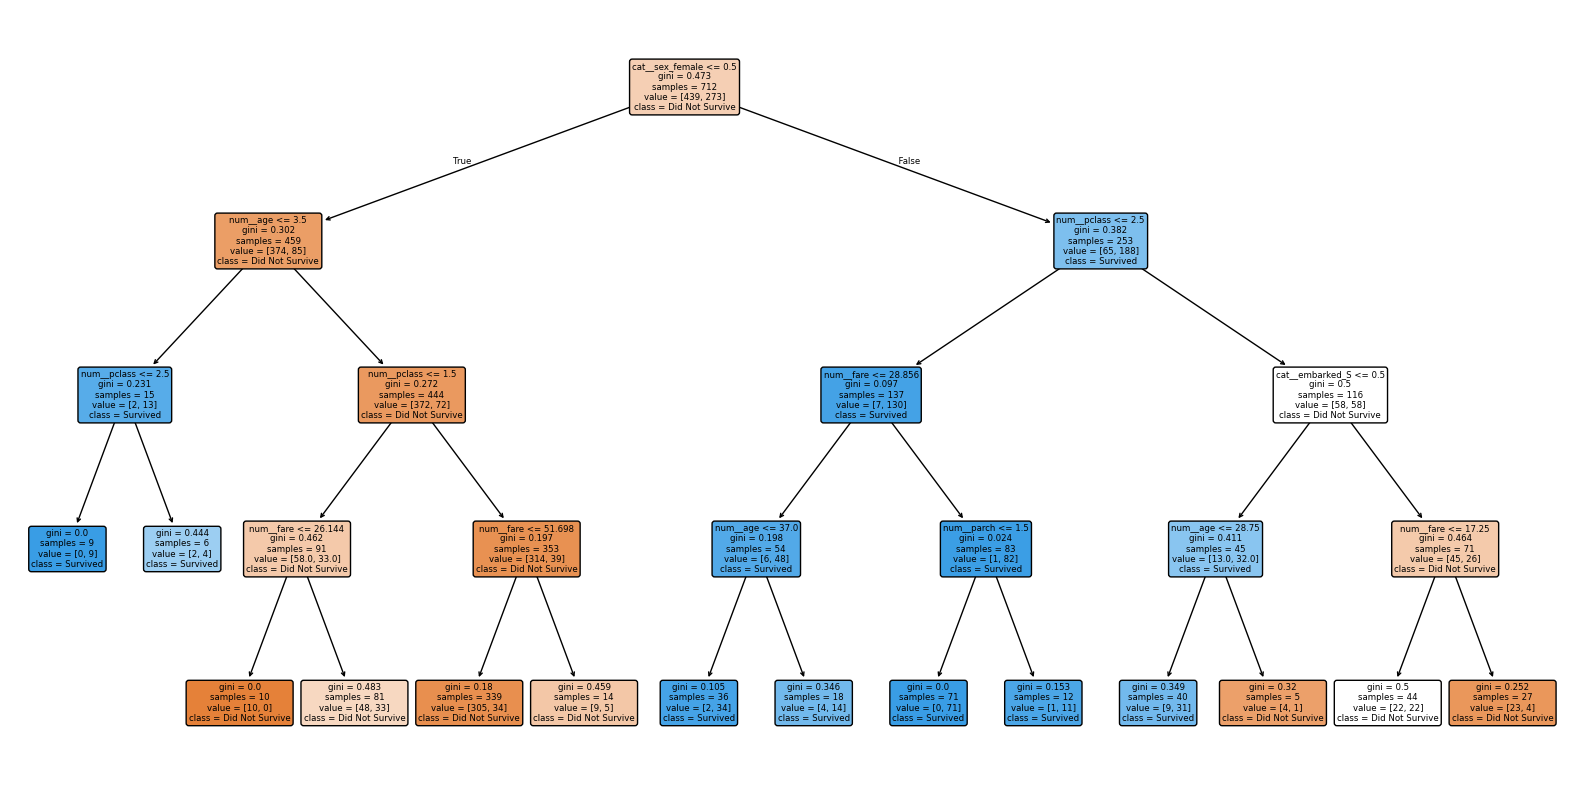

In [61]:
# Create CART Decision Tree model
cart_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train model
cart_model.fit(X_train_processed, y_train)

# Predict testing data
y_pred = cart_model.predict(X_test_processed)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("CART Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Did Not Survive", "Survived"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CART Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualize decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["Did Not Survive", "Survived"],
    filled=True,
    rounded=True
)

plt.show()

# Step 7: New Passenger Prediction and Model Saving

## Objective
Use the trained CART model to predict the survival status of new passengers and save the trained model for future use.

## New Passenger Prediction

Provide passenger information such as:
- Passenger Class
- Gender
- Age
- Number of Siblings or Spouses
- Number of Parents or Children
- Ticket Fare
- Embarkation Port

## Prediction Process
1. Create new passenger input.
2. Apply the fitted preprocessing pipeline.
3. Generate the survival prediction.
4. Calculate prediction probabilities.
5. Display the result.

## Model Persistence

Save the following files using Joblib:
- cart_model.pkl
- preprocessor.pkl

## Expected Outcome
Successfully predict passenger survival and save the trained model and preprocessing pipeline for future predictions.

In [62]:
# Create a new passenger
new_passenger = pd.DataFrame({
    "pclass": [1],
    "sex": ["female"],
    "age": [25],
    "sibsp": [0],
    "parch": [0],
    "fare": [80.0],
    "embarked": ["C"]
})

# Preprocess new passenger
passenger_processed = preprocessor.transform(new_passenger)

# Predict survival
prediction = cart_model.predict(passenger_processed)

# Calculate probabilities
probability = cart_model.predict_proba(passenger_processed)

# Display prediction
print(
    "Prediction:",
    "Survived" if prediction[0] == 1 else "Did Not Survive"
)

print("Survival Probability:", round(probability[0][1] * 100, 2), "%")

# Save model and preprocessing pipeline
joblib.dump(cart_model, "cart_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("\nModel and Preprocessor Saved Successfully!")

Prediction: Survived
Survival Probability: 100.0 %

Model and Preprocessor Saved Successfully!


# Project Conclusion and Key Learnings

## 1. What Did I Learn?

- Understood the complete machine learning workflow, from data loading to prediction.
- Learned how to identify and handle missing values using imputation.
- Used exploratory data analysis to understand passenger survival patterns.
- Converted categorical features into numerical values using One-Hot Encoding.
- Trained and evaluated a machine learning classification model.
- Learned how to save and reuse trained models using Joblib.

## 2. Why Did I Choose CART?

I selected CART (Classification and Regression Tree) because:

- It is easy to understand and interpret.
- It handles classification problems effectively.
- It makes decisions using simple feature-based conditions.
- It does not require feature scaling.
- Its decision tree visualization helps explain how predictions are made.

## 3. What Made a Difference in This Project?

- **Gender:** Helped identify differences in survival patterns.
- **Passenger Class:** Highlighted differences in survival rates across classes.
- **Age:** Helped the model consider passenger age.
- **Missing Value Imputation:** Allowed the model to use records with missing values.
- **One-Hot Encoding:** Converted categorical information into a format suitable for the model.
- **Tree Parameters:** Gini criterion, maximum depth, and minimum sample settings helped control tree complexity and reduce overfitting.
- **Stratified Train-Test Split:** Maintained the target class distribution across training and testing data.

## 4. Model Performance

- Algorithm: CART Decision Tree Classifier
- Testing Accuracy: 77.65%
- Training Data: 80%
- Testing Data: 20%

The model performed better at identifying passengers who did not survive than those who survived. This indicates that further model tuning could improve survivor detection.

## 5. Final Conclusion

This project helped me understand how a CART decision tree learns patterns from historical data and uses them to make predictions.

I gained practical experience in data preprocessing, exploratory data analysis, model training, evaluation, prediction, and model persistence.

The project demonstrates a complete machine learning classification workflow using Python and Scikit-learn.